# Sneha Singh
## DATA 266 — Homework 7
GANs in theory, then a fully connected autoencoder and a VAE on FashionMNIST


In [1]:
# Step 0: Libraries & Student Parameters
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.manifold import TSNE

# Robust path handling: works whether launched from Gen-Ai/ or HW-7/
CURRENT_DIR = Path.cwd()
if CURRENT_DIR.name == "HW-7":
    ROOT = CURRENT_DIR
else:
    ROOT = CURRENT_DIR / "HW-7"

DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "figures"
CKPT_DIR = ROOT / "checkpoints"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# last 4 of my SJSUid - 0670
SID4 = 670
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# set seeds for python, numpy, torch
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))

print("SID4: ", SID4)
print("SEED: ", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)
print("Device:", device)
print("ROOT:  ", ROOT)


SID4:  670
SEED:  670
SLICE: 670
HP_ID: 4
CLS_A: 0
CLS_B: 5
Device: mps
ROOT:   /Users/snehasingh/Desktop/Gen-Ai/HW-7


This assignment said follow the same step 0 as assignment 1. I did not copy the HW1 diabetes notebook. I only reused the standing parameters: SID4=670, SEED=670, SLICE=670, HP_ID=4, CLS_A=0, CLS_B=5, and I seeded python / numpy / torch with 670.

HW1 used HP_ID for a second network (15 vs 30 epochs). This assignment said skip that. The FC-AE and the VAE are the two trained models.

CLS_A=0 (T-shirt/top) and CLS_B=5 (Sandal) are the two classes for the latent interpolation in section 4. This ran on my Mac (MPS) in about 4 minutes.


## 1. GAN architecture

A GAN has two networks. The generator G takes noise z ~ N(0, I) and outputs a fake sample. The discriminator D takes a sample and outputs the probability that it is real.

They play a minimax game:

min_G max_D  E[log D(x)] + E[log(1 − D(G(z)))]

Training alternates. In the D step, G is frozen and D is pushed to give high scores to real data and low scores to G's samples. In the G step, D is frozen and G is pushed to make D score its samples as real. In practice G maximizes log D(G(z)) instead of minimizing log(1 − D(G(z))), because early on D wins easily and the original loss gives G almost no gradient.

The goal is that the generator's distribution p_g matches the data distribution p_data. For a fixed G the best discriminator is D*(x) = p_data(x) / (p_data(x) + p_g(x)). Putting that back in, G is minimizing 2·JSD(p_data ‖ p_g) − log 4. That is smallest when p_g = p_data, and then D* = 1/2 everywhere, so D cannot tell real from fake. Real training does not reach this. Both networks are non-convex and update at the same time, so the losses can oscillate instead of settling.


## 2. Mode collapse

Mode collapse is when G only produces a few kinds of samples (a few digits out of ten, one kind of shirt) even though the data has many. Many different z map to nearly the same output.

Why it happens: D scores each sample on its own, so nothing in the loss rewards G for being diverse. G is rewarded for whatever D currently scores highest, so it moves to that point. Then D learns to reject it, G jumps to a different point, and this repeats instead of G covering all the modes. When D is too strong, or when the real and fake distributions do not overlap, the JS-based loss also gives G almost no gradient.

Two fixes:

1. **WGAN-GP.** D becomes a critic that estimates the Wasserstein distance, with no sigmoid or log. It must be 1-Lipschitz, which is enforced with a penalty λ(‖∇D(x̂)‖ − 1)² on points x̂ between real and fake. The Wasserstein distance still gives a useful gradient when the two distributions do not overlap, so I can train the critic well without G's gradient vanishing, and G has no single sharp peak to jump to.
2. **Minibatch discrimination.** D gets features that compare each sample with the others in the same batch. A batch where G outputs near-identical samples is easy for D to flag as fake. That pushes G to make each batch diverse.


## 3. Three GAN variants

**DCGAN** (Radford et al., 2015). The first GANs used fully connected layers and were unstable on images. DCGAN uses strided convolutions instead of pooling, transposed convolutions in G, batch norm in both, ReLU in G (Tanh at the output) and LeakyReLU in D, and no fully connected hidden layers. Training on images became stable enough to use.

**Conditional GAN** (Mirza & Osindero, 2014). A plain GAN gives no control over what it generates. A cGAN feeds a label y (a class, or an input image in pix2pix) to both G and D. D now judges whether the sample is real for that label, so G has to produce the class that was asked for. Pix2pix uses this with paired images and adds an L1 loss and a patch-based D.

**CycleGAN** (Zhu et al., 2017). Image-to-image translation needed paired examples. CycleGAN trains two generators (X to Y and Y to X) and two discriminators with a cycle-consistency loss: F(G(x)) ≈ x and G(F(y)) ≈ y. That loss ties the output to the input content, so it works on unpaired sets such as horses and zebras.


## 4. FC-AE vs VAE on FashionMNIST

60,000 train and 10,000 test images, 28×28 grayscale, pixels 0 to 1. Both models use 784-512-128-20 for the encoder and the mirror image for the decoder, with a sigmoid on the output. Latent size is 20. Adam, lr 1e-3, batch 128, 20 epochs.

Loss is binary cross-entropy summed over the 784 pixels, averaged over the batch. The VAE has two heads, μ and log σ², samples z = μ + σ·ε, and adds the KL term to N(0, I). KL weight is 1.


In [2]:
# Load FashionMNIST Dataset
transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(f"Train samples: {len(train_dataset):,}")
print(f"Test samples:  {len(test_dataset):,}")
print(f"Image shape:   {train_dataset[0][0].shape} (28x28 grayscale)")
print("Classes:", class_names)


Train samples: 60,000
Test samples:  10,000
Image shape:   torch.Size([1, 28, 28]) (28x28 grayscale)
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [3]:
LATENT_DIM = 20

# Model 1: Fully Connected AutoEncoder (FC-AE)
class FCAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        # Encoder: 784 -> 512 -> 128 -> 20
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(True),
            nn.Linear(512, 128),
            nn.ReLU(True),
            nn.Linear(128, latent_dim)
        )
        # Decoder: 20 -> 128 -> 512 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(True),
            nn.Linear(128, 512),
            nn.ReLU(True),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x.view(-1, 784))
        recon = self.decode(z)
        return recon, z

# Model 2: Variational AutoEncoder (VAE)
class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        # Encoder backbone
        self.enc_backbone = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(True),
            nn.Linear(512, 128),
            nn.ReLU(True)
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.ReLU(True),
            nn.Linear(128, 512),
            nn.ReLU(True),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.enc_backbone(x.view(-1, 784))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar, z

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

fc_ae = FCAE().to(device)
vae = VAE().to(device)

print(f"FC-AE Trainable Parameters: {count_params(fc_ae):,}")
print(f"VAE Trainable Parameters:   {count_params(vae):,}")


FC-AE Trainable Parameters: 941,092
VAE Trainable Parameters:   943,672


In [4]:
# Loss functions
def fc_ae_loss(recon_x, x):
    return F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction="sum") / x.size(0)

def vae_loss_fn(recon_x, x, mu, logvar):
    recon_loss = F.binary_cross_entropy(recon_x, x.view(-1, 784), reduction="sum") / x.size(0)
    kl_div = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    total_loss = recon_loss + kl_div
    return total_loss, recon_loss, kl_div

epochs = 20
lr = 1e-3
opt_ae = torch.optim.Adam(fc_ae.parameters(), lr=lr)

print("--- Training Fully Connected AutoEncoder (FC-AE) ---")
ae_train_losses = []
start_ae = time.time()
for epoch in range(1, epochs + 1):
    fc_ae.train()
    running_loss = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_ae.zero_grad()
        recon, _ = fc_ae(x)
        loss = fc_ae_loss(recon, x)
        loss.backward()
        opt_ae.step()
        running_loss += loss.item() * x.size(0)
    epoch_loss = running_loss / len(train_dataset)
    ae_train_losses.append(epoch_loss)
    print(f"FC-AE Epoch [{epoch:2d}/{epochs}] - Train Loss (BCE): {epoch_loss:.4f}")

print(f"FC-AE training finished in {time.time() - start_ae:.2f}s")
torch.save(fc_ae.state_dict(), CKPT_DIR / "fc_ae.pt")


--- Training Fully Connected AutoEncoder (FC-AE) ---


FC-AE Epoch [ 1/20] - Train Loss (BCE): 267.6440


FC-AE Epoch [ 2/20] - Train Loss (BCE): 233.2876


FC-AE Epoch [ 3/20] - Train Loss (BCE): 226.7644


FC-AE Epoch [ 4/20] - Train Loss (BCE): 223.2539


...

FC-AE Epoch [16/20] - Train Loss (BCE): 212.2057


FC-AE Epoch [17/20] - Train Loss (BCE): 211.9399


FC-AE Epoch [18/20] - Train Loss (BCE): 211.6879


FC-AE Epoch [19/20] - Train Loss (BCE): 211.5006


FC-AE Epoch [20/20] - Train Loss (BCE): 211.3226
FC-AE training finished in 109.43s


In [5]:
opt_vae = torch.optim.Adam(vae.parameters(), lr=lr)

print("--- Training Variational AutoEncoder (VAE) ---")
vae_train_losses = []
vae_train_recons = []
vae_train_kls = []
start_vae = time.time()
for epoch in range(1, epochs + 1):
    vae.train()
    running_total = 0.0
    running_recon = 0.0
    running_kl = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        opt_vae.zero_grad()
        recon, mu, logvar, _ = vae(x)
        total_loss, recon_loss, kl_div = vae_loss_fn(recon, x, mu, logvar)
        total_loss.backward()
        opt_vae.step()
        running_total += total_loss.item() * x.size(0)
        running_recon += recon_loss.item() * x.size(0)
        running_kl += kl_div.item() * x.size(0)
    epoch_total = running_total / len(train_dataset)
    epoch_recon = running_recon / len(train_dataset)
    epoch_kl = running_kl / len(train_dataset)
    vae_train_losses.append(epoch_total)
    vae_train_recons.append(epoch_recon)
    vae_train_kls.append(epoch_kl)
    print(f"VAE Epoch [{epoch:2d}/{epochs}] - Total: {epoch_total:.4f} | Recon: {epoch_recon:.4f} | KL: {epoch_kl:.4f}")

print(f"VAE training finished in {time.time() - start_vae:.2f}s")
torch.save(vae.state_dict(), CKPT_DIR / "vae.pt")


--- Training Variational AutoEncoder (VAE) ---


VAE Epoch [ 1/20] - Total: 291.3547 | Recon: 279.8671 | KL: 11.4876


VAE Epoch [ 2/20] - Total: 257.3314 | Recon: 245.4273 | KL: 11.9040


VAE Epoch [ 3/20] - Total: 249.8804 | Recon: 238.4530 | KL: 11.4274


VAE Epoch [ 4/20] - Total: 246.6321 | Recon: 235.1694 | KL: 11.4627


...

VAE Epoch [16/20] - Total: 238.4806 | Recon: 225.6174 | KL: 12.8632


VAE Epoch [17/20] - Total: 238.2579 | Recon: 225.3797 | KL: 12.8782


VAE Epoch [18/20] - Total: 238.0735 | Recon: 225.1811 | KL: 12.8924


VAE Epoch [19/20] - Total: 237.9359 | Recon: 225.0122 | KL: 12.9237


VAE Epoch [20/20] - Total: 237.7973 | Recon: 224.8707 | KL: 12.9265
VAE training finished in 115.63s


In [6]:
# Quantitative Evaluation on Test Set
fc_ae.eval()
vae.eval()

ae_test_bce = 0.0
ae_test_mse = 0.0
vae_test_bce = 0.0
vae_test_mse = 0.0
vae_test_kl = 0.0

with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        flat_x = x.view(-1, 784)
        
        # FC-AE
        recon_ae, _ = fc_ae(x)
        ae_test_bce += F.binary_cross_entropy(recon_ae, flat_x, reduction="sum").item()
        ae_test_mse += F.mse_loss(recon_ae, flat_x, reduction="sum").item()
        
        # VAE
        recon_vae, mu, logvar, _ = vae(x)
        vae_test_bce += F.binary_cross_entropy(recon_vae, flat_x, reduction="sum").item()
        vae_test_mse += F.mse_loss(recon_vae, flat_x, reduction="sum").item()
        vae_test_kl += (-0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())).item()

n_test = len(test_dataset)
ae_test_bce /= n_test
ae_test_mse /= (n_test * 784)
vae_test_bce /= n_test
vae_test_mse /= (n_test * 784)
vae_test_kl /= n_test

print("==========================================================")
print("             QUANTITATIVE TEST SET EVALUATION             ")
print("==========================================================")
print(f"FC-AE Test BCE Loss (per image): {ae_test_bce:.4f}")
print(f"FC-AE Test MSE Loss (per pixel): {ae_test_mse:.6f}")
print("----------------------------------------------------------")
print(f"VAE Test Recon BCE (per image):  {vae_test_bce:.4f}")
print(f"VAE Test Recon MSE (per pixel):  {vae_test_mse:.6f}")
print(f"VAE Test KL Divergence:          {vae_test_kl:.4f}")
print(f"VAE Total Test Loss (BCE + KL):  {(vae_test_bce + vae_test_kl):.4f}")
print("==========================================================")


             QUANTITATIVE TEST SET EVALUATION             
FC-AE Test BCE Loss (per image): 213.6070
FC-AE Test MSE Loss (per pixel): 0.009739
----------------------------------------------------------
VAE Test Recon BCE (per image):  226.8435
VAE Test Recon MSE (per pixel):  0.015663
VAE Test KL Divergence:          13.0439
VAE Total Test Loss (BCE + KL):  239.8874


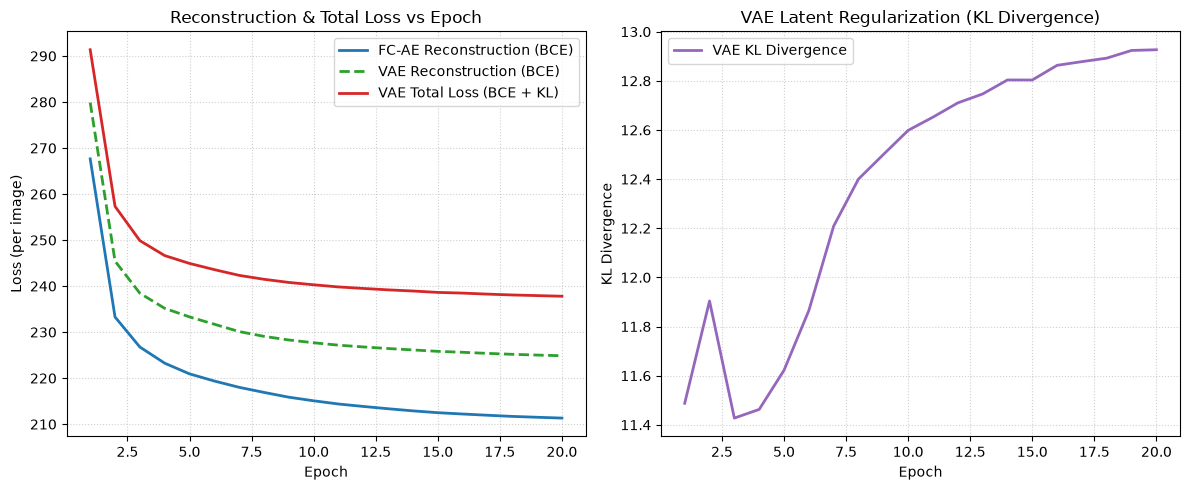

In [7]:
# 1. Plot Training Loss Curves
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), ae_train_losses, label="FC-AE Reconstruction (BCE)", color="#1f77b4", lw=2)
plt.plot(range(1, epochs + 1), vae_train_recons, label="VAE Reconstruction (BCE)", color="#2ca02c", lw=2, linestyle="--")
plt.plot(range(1, epochs + 1), vae_train_losses, label="VAE Total Loss (BCE + KL)", color="#d62728", lw=2)
plt.xlabel("Epoch")
plt.ylabel("Loss (per image)")
plt.title("Reconstruction & Total Loss vs Epoch")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), vae_train_kls, label="VAE KL Divergence", color="#9467bd", lw=2)
plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.title("VAE Latent Regularization (KL Divergence)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "loss_curves.png", dpi=300)
plt.show()


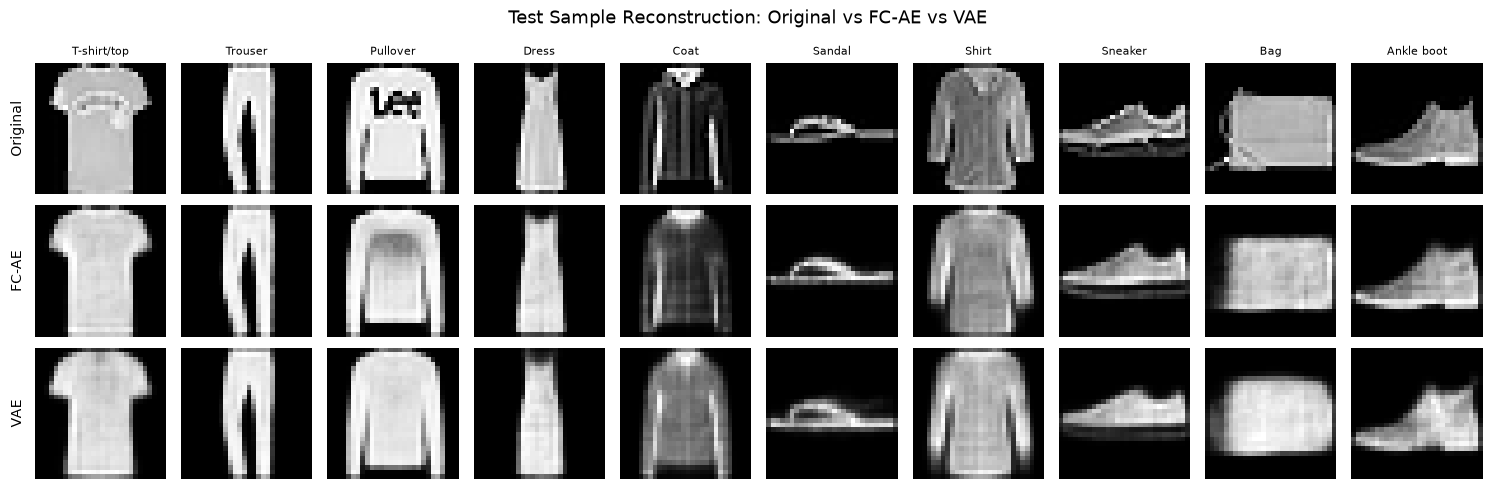

In [8]:
# 2. Visual Reconstruction Comparison across 10 Classes
samples_per_class = {}
for img, label in test_dataset:
    if label not in samples_per_class:
        samples_per_class[label] = img
    if len(samples_per_class) == 10:
        break

ordered_imgs = [samples_per_class[c] for c in range(10)]
batch_imgs = torch.stack(ordered_imgs).to(device)

with torch.no_grad():
    recon_ae_imgs, _ = fc_ae(batch_imgs)
    recon_vae_imgs, _, _, _ = vae(batch_imgs)

recon_ae_imgs = recon_ae_imgs.view(-1, 28, 28).cpu().numpy()
recon_vae_imgs = recon_vae_imgs.view(-1, 28, 28).cpu().numpy()
orig_imgs = batch_imgs.view(-1, 28, 28).cpu().numpy()

fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for col in range(10):
    # Original
    axes[0, col].imshow(orig_imgs[col], cmap="gray")
    axes[0, col].axis("off")
    axes[0, col].set_title(class_names[col], fontsize=8)
    # FC-AE
    axes[1, col].imshow(recon_ae_imgs[col], cmap="gray")
    axes[1, col].axis("off")
    # VAE
    axes[2, col].imshow(recon_vae_imgs[col], cmap="gray")
    axes[2, col].axis("off")

for row, name in enumerate(["Original", "FC-AE", "VAE"]):
    axes[row, 0].text(-0.08, 0.5, name, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=10)
fig.suptitle("Test Sample Reconstruction: Original vs FC-AE vs VAE", fontsize=13, y=0.98)
plt.tight_layout()
plt.savefig(FIG_DIR / "reconstructions_comparison.png", dpi=300)
plt.show()


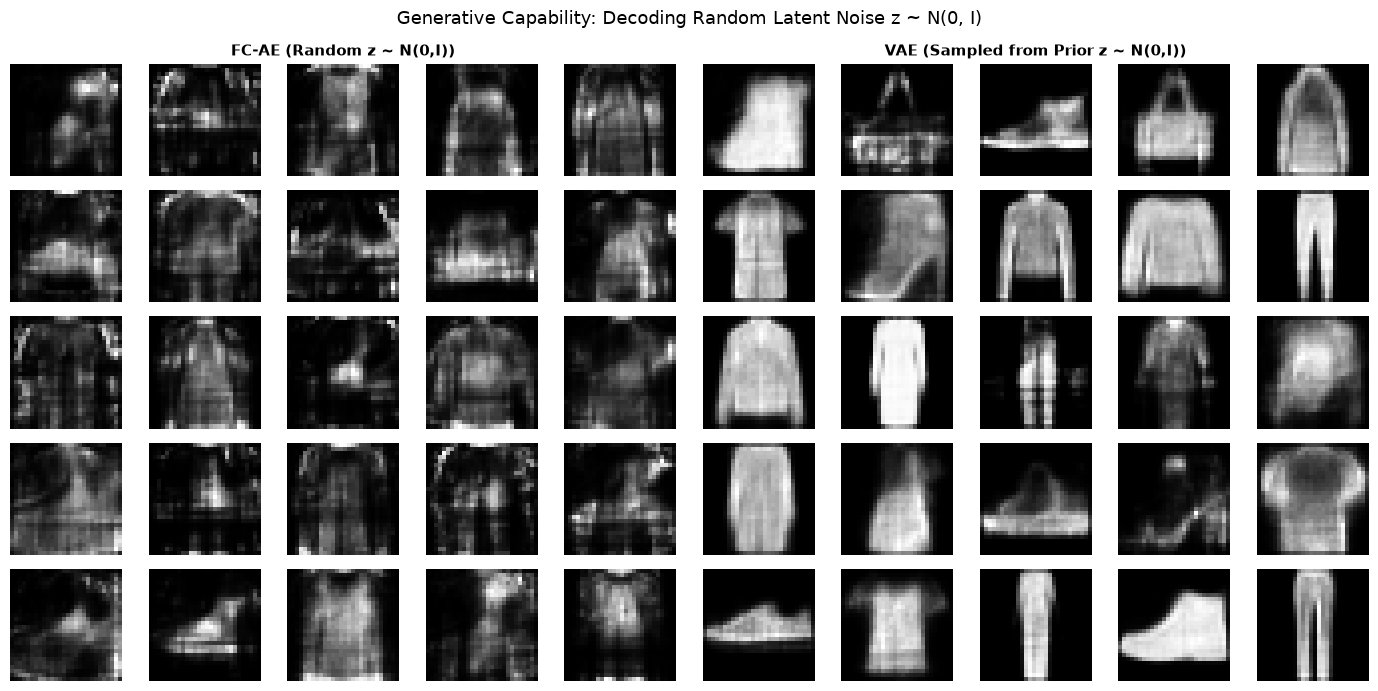

In [9]:
# 3. Random Generation from Latent Prior z ~ N(0, I)
n_samples = 25
torch.manual_seed(SEED)
z_prior = torch.randn(n_samples, LATENT_DIM).to(device)

with torch.no_grad():
    gen_ae = fc_ae.decode(z_prior).view(-1, 28, 28).cpu().numpy()
    gen_vae = vae.decode(z_prior).view(-1, 28, 28).cpu().numpy()

fig, axes = plt.subplots(5, 10, figsize=(14, 7))
for i in range(25):
    r, c = divmod(i, 5)
    # FC-AE on left 5 cols
    axes[r, c].imshow(gen_ae[i], cmap="gray")
    axes[r, c].axis("off")
    # VAE on right 5 cols
    axes[r, c + 5].imshow(gen_vae[i], cmap="gray")
    axes[r, c + 5].axis("off")

axes[0, 2].set_title("FC-AE (Random z ~ N(0,I))", fontsize=11, fontweight="bold")
axes[0, 7].set_title("VAE (Sampled from Prior z ~ N(0,I))", fontsize=11, fontweight="bold")
fig.suptitle("Generative Capability: Decoding Random Latent Noise z ~ N(0, I)", fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "random_generation.png", dpi=300)
plt.show()


### Latent interpolation (CLS_A=0 to CLS_B=5)

First T-shirt and first sandal in the test set. I encode both (the VAE uses μ), blend the two latent codes in 10 even steps, and decode. Top row FC-AE, bottom row VAE.


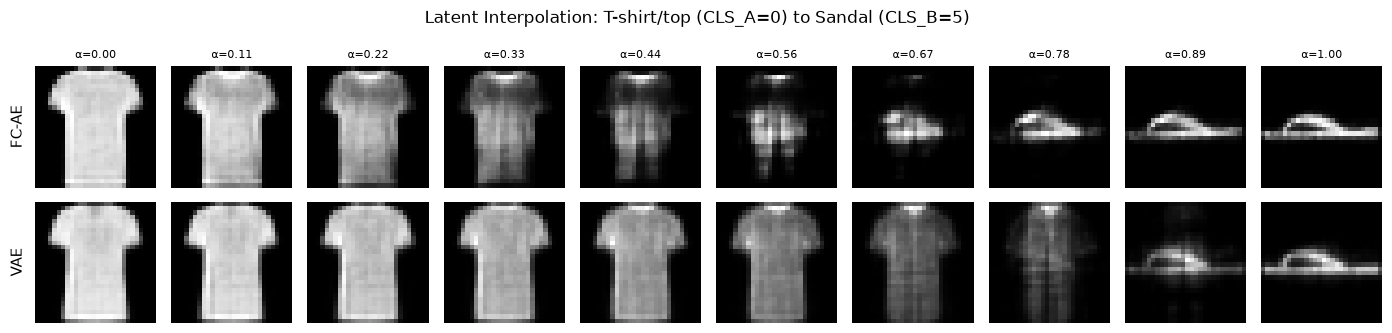

In [10]:
# 4. Latent Space Linear Interpolation between CLS_A (0: T-shirt) and CLS_B (5: Sandal)
idx_a = None
idx_b = None
for idx, (img, label) in enumerate(test_dataset):
    if label == CLS_A and idx_a is None:
        idx_a = idx
    elif label == CLS_B and idx_b is None:
        idx_b = idx
    if idx_a is not None and idx_b is not None:
        break

img_a, _ = test_dataset[idx_a]
img_b, _ = test_dataset[idx_b]
pair_imgs = torch.stack([img_a, img_b]).to(device)

with torch.no_grad():
    z_ae_a = fc_ae.encode(pair_imgs[0:1].view(1, -1))
    z_ae_b = fc_ae.encode(pair_imgs[1:2].view(1, -1))
    mu_a, _ = vae.encode(pair_imgs[0:1].view(1, -1))
    mu_b, _ = vae.encode(pair_imgs[1:2].view(1, -1))

steps = 10
alphas = np.linspace(0, 1, steps)
interp_ae = []
interp_vae = []

with torch.no_grad():
    for alpha in alphas:
        z_ae_interp = (1 - alpha) * z_ae_a + alpha * z_ae_b
        z_vae_interp = (1 - alpha) * mu_a + alpha * mu_b
        out_ae = fc_ae.decode(z_ae_interp).view(28, 28).cpu().numpy()
        out_vae = vae.decode(z_vae_interp).view(28, 28).cpu().numpy()
        interp_ae.append(out_ae)
        interp_vae.append(out_vae)

fig, axes = plt.subplots(2, steps, figsize=(14, 3.5))
for col, alpha in enumerate(alphas):
    axes[0, col].imshow(interp_ae[col], cmap="gray")
    axes[0, col].axis("off")
    axes[0, col].set_title(f"α={alpha:.2f}", fontsize=8)
    axes[1, col].imshow(interp_vae[col], cmap="gray")
    axes[1, col].axis("off")

for row, name in enumerate(["FC-AE", "VAE"]):
    axes[row, 0].text(-0.08, 0.5, name, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="right", fontsize=11)
fig.suptitle(f"Latent Interpolation: {class_names[CLS_A]} (CLS_A=0) to {class_names[CLS_B]} (CLS_B=5)", fontsize=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "latent_interpolation.png", dpi=300)
plt.show()


### t-SNE

First 2,000 test images, 20-d latent code (VAE uses μ), perplexity 30, seed 670.


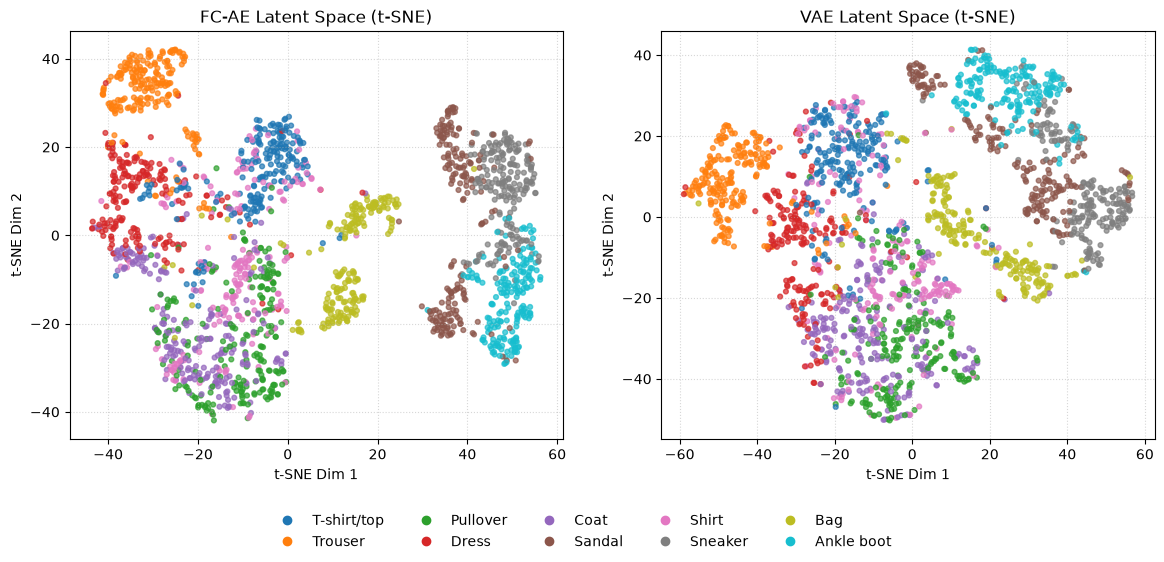

In [11]:
# 5. Latent Space t-SNE Projection (2,000 test points)
n_eval = 2000
subset_loader = DataLoader(test_dataset, batch_size=n_eval, shuffle=False)
x_sub, y_sub = next(iter(subset_loader))
x_sub = x_sub.to(device)

with torch.no_grad():
    _, z_ae_eval = fc_ae(x_sub)
    _, mu_vae_eval, _, _ = vae(x_sub)

z_ae_np = z_ae_eval.cpu().numpy()
z_vae_np = mu_vae_eval.cpu().numpy()
y_np = y_sub.numpy()

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
tsne_ae = tsne.fit_transform(z_ae_np)
tsne_vae = tsne.fit_transform(z_vae_np)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
scatter_ae = plt.scatter(tsne_ae[:, 0], tsne_ae[:, 1], c=y_np, cmap="tab10", alpha=0.7, s=12)
plt.title("FC-AE Latent Space (t-SNE)", fontsize=12)
plt.xlabel("t-SNE Dim 1")
plt.ylabel("t-SNE Dim 2")
plt.grid(True, linestyle=":", alpha=0.5)

plt.subplot(1, 2, 2)
scatter_vae = plt.scatter(tsne_vae[:, 0], tsne_vae[:, 1], c=y_np, cmap="tab10", alpha=0.7, s=12)
plt.title("VAE Latent Space (t-SNE)", fontsize=12)
plt.xlabel("t-SNE Dim 1")
plt.ylabel("t-SNE Dim 2")
plt.grid(True, linestyle=":", alpha=0.5)

handles = [plt.Line2D([0], [0], marker="o", ls="", color=plt.cm.tab10(c / 9), label=class_names[c], markersize=6)
           for c in range(10)]
plt.figlegend(handles=handles, loc="lower center", ncol=5, frameon=False)
plt.subplots_adjust(bottom=0.2)

plt.savefig(FIG_DIR / "latent_tsne.png", dpi=300, bbox_inches="tight")
plt.show()


## Comparison

Test set, all 10,000 images.

| | FC-AE | VAE |
|--|------:|----:|
| Recon BCE per image | 213.6070 | 226.8435 |
| Recon MSE per pixel | 0.009739 | 0.015663 |
| KL per image | none | 13.0439 |
| BCE + KL | 213.6070 | 239.8874 |

The last row is not a fair comparison, since the FC-AE has no KL term.

FC-AE reconstructs better. Nothing pulls its latent code toward a prior, so all 20 dimensions go to reconstruction. In the reconstruction figure the VAE copies are blurrier, especially the bag and the ankle boot. Both lose the print on the pullover.

Random z is where it flips. I decode z ~ N(0, I) in both. The FC-AE gives smudges and stripes, and almost none look like clothing. The VAE gives sneakers, boots, trousers, a dress, shirts and a bag, though some are blurry or mixed. The KL term (13.04) pulls the VAE codes toward N(0, I), so a random z lands where the decoder was trained. The FC-AE has no reason to use that region.

Interpolation did not come out the way I expected. The FC-AE fades slowly: the middle frames are a smudge of shirt and sandal, and it is a sandal by about α=0.8. The VAE stays shirt-shaped and fades until about α=0.8, then is a sandal by α=0.9. I do not see a clean in-between item in either row. This is one pair, so I would not claim more.

t-SNE: both separate trousers, bags and the shoe classes. T-shirt, pullover, coat and shirt overlap in both. I cannot see a clear difference between the two plots, so I am not claiming the VAE clusters are better.

If I need to compress and rebuild images, I would use the FC-AE. If I need to sample new images, I would use the VAE.
